# Model

**How accurately can trip characteristics predict recorded tip percentage for card-paid NYC yellow taxi trips, and which features contribute most?** We also examine whether knowing a trip took place in February or December improves predictions and how the fitted model's predictions differ between those months for the same trip inputs.

Run **clean data** first. This notebook needs pandas, PyArrow, Matplotlib, and scikit-learn. It uses only February and December, with a chronological split. The team previously profiled 2025 descriptively. Model settings are selected on 2024 before the notebook loads 2025 for evaluation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SAMPLE_DIR = ROOT / "data" / "sample"
SEED = 42
THREADS = 4

ZONE_FEATURES = ["PULocationID", "DOLocationID"]
TRIP_FEATURES = ZONE_FEATURES + ["fare_amount", "trip_distance", "duration_min", "hour", "dow"]
ALL_FEATURES = TRIP_FEATURES + ["is_december"]
TARGET = "tip_pct_total"
BASELINE_KEYS = ["PULocationID", "hour"]
COLUMNS = TRIP_FEATURES + [TARGET, "month_name", "tip_amount", "tip_over_100_pct"]


def load_trips(years):
    trips = pd.concat(
        [pd.read_parquet(SAMPLE_DIR / f"sample_{year}-{month}.parquet", columns=COLUMNS)
         for year in years for month in ("02", "12")],
        ignore_index=True,
    )
    return trips.assign(is_december=trips["month_name"].eq("Dec").astype("int8"))


development = load_trips([2022, 2023])
validation = load_trips([2024])
pd.Series({"Development trips": len(development), "Validation trips": len(validation)})

Development trips    1000000
Validation trips      500000
dtype: int64

## Benchmark and gradient boosting

The target is 100 × tip amount ÷ full pre-tip charge. The prediction is made at the end of the ride, before the tip is entered. Fare, distance, duration, pickup and drop-off zone, pickup hour, and day of week are available then. The explicit feature list keeps the recorded tip, total amount, tip-derived flags, and exact dates out of the predictors. The month version adds only the December indicator.

The historical benchmark uses average training tip percentage by pickup zone and hour, with the overall training mean as a fallback. Histogram gradient boosting can model nonlinear relationships and interactions. Its zone encoder learns categories from the fitting data, groups the least frequent categories if a zone column exceeds 255 categories, and passes unseen zones to the model as missing categories.

In [2]:
def make_model(max_leaves):
    encoder = OrdinalEncoder(
        max_categories=255, handle_unknown="use_encoded_value", unknown_value=float("nan")
    )
    preprocessing = ColumnTransformer(
        [("zones", encoder, ZONE_FEATURES)], remainder="passthrough"
    )
    # The transformer places encoded pickup and drop-off zones first.
    model = HistGradientBoostingRegressor(
        categorical_features=[0, 1], max_leaf_nodes=max_leaves,
        max_iter=100, learning_rate=0.1, min_samples_leaf=100,
        early_stopping=False, random_state=SEED,
    )
    return make_pipeline(preprocessing, model)


def fit_model(trips, features, max_leaves):
    with threadpool_limits(limits=THREADS):
        return make_model(max_leaves).fit(trips[features], trips[TARGET])


def predict(model, trips, features):
    with threadpool_limits(limits=THREADS):
        return model.predict(trips[features])


def historical_prediction(training, trips):
    historical_means = training.groupby(BASELINE_KEYS)[TARGET].mean()
    keys = pd.MultiIndex.from_frame(trips[BASELINE_KEYS])
    return historical_means.reindex(keys).fillna(training[TARGET].mean()).to_numpy()

## Choose settings on 2024

Compare two tree sizes with the same feature set. Select the one with lower validation mean absolute error (MAE), then use those settings for both final boosted models. MAE is the average size of a prediction error in percentage points.

In [3]:
validation_models = {}
validation_errors = {}
for max_leaves in (15, 31):
    model = fit_model(development, ALL_FEATURES, max_leaves)
    validation_models[max_leaves] = model
    validation_errors[max_leaves] = mean_absolute_error(
        validation[TARGET], predict(model, validation, ALL_FEATURES)
    )

best_leaves = min(validation_errors, key=validation_errors.get)
display(pd.Series(validation_errors, name="2024 MAE (pp)").rename_axis("Max leaves").round(4))
validation_benchmark = historical_prediction(development, validation)
print(f"Selected max leaves: {best_leaves}.")
print(f"Historical benchmark validation MAE: "
      f"{mean_absolute_error(validation[TARGET], validation_benchmark):.4f} pp.")

Selected max leaves: 15.
Historical benchmark validation MAE: 4.8870 pp.


Max leaves
15    4.8965
31    4.9050
Name: 2024 MAE (pp), dtype: float64

## Which features matter most?

Use a reproducible 30,000-trip sample from 2024 and shuffle one input at a time, five times. A larger increase in MAE means the fitted model relied more on that feature. The bars show the standard deviation across the five shuffles. Related features such as fare, distance, and duration can carry overlapping information, so the ranking describes the fitted model's reliance on each input.

,Mean MAE increase (pp),Shuffle SD (pp)
Fare,0.6066,0.0097
Pickup zone,0.1993,0.0072
Duration,0.1262,0.0019
Drop-off zone,0.1131,0.0029
Distance,0.0640,0.0039
Pickup hour,0.0118,0.0010
December indicator,0.0012,0.0012
Day of week,0.0006,0.0003


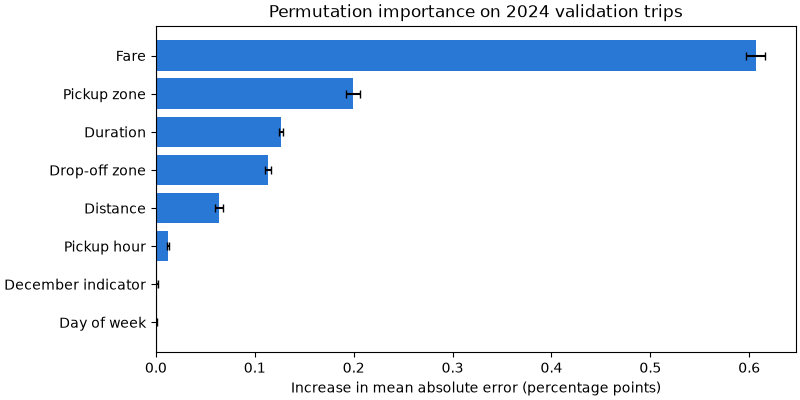

In [4]:
importance_trips = validation.sample(n=30_000, random_state=SEED)
with threadpool_limits(limits=THREADS):
    importance = permutation_importance(
        validation_models[best_leaves], importance_trips[ALL_FEATURES],
        importance_trips[TARGET], scoring="neg_mean_absolute_error",
        n_repeats=5, random_state=SEED,
    )

feature_names = ["Pickup zone", "Drop-off zone", "Fare", "Distance", "Duration",
                 "Pickup hour", "Day of week", "December indicator"]
importance_table = pd.DataFrame({
    "Mean MAE increase (pp)": importance.importances_mean,
    "Shuffle SD (pp)": importance.importances_std,
}, index=feature_names).sort_values("Mean MAE increase (pp)", ascending=False)
display(importance_table.round(4))

plot_data = importance_table.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.barh(plot_data.index, plot_data["Mean MAE increase (pp)"],
        xerr=plot_data["Shuffle SD (pp)"], color="#2a78d6", capsize=3)
ax.axvline(0, color="#444444", linewidth=0.8)
ax.set(title="Permutation importance on 2024 validation trips",
       xlabel="Increase in mean absolute error (percentage points)")
plt.show()

## Evaluate on February and December 2025

Refit the benchmark and both boosted models on February and December 2022–2024. Compare predictions on the same 2025 trips. The primary test includes all eligible trips. The zero-tip rows diagnose performance on a distinct outcome, and the sensitivity rows show scores after omitting flagged tips above 100% from scoring. All rows use the same fitted models.

In [5]:
training = pd.concat([development, validation], ignore_index=True)
without_month = fit_model(training, TRIP_FEATURES, best_leaves)
with_month = fit_model(training, ALL_FEATURES, best_leaves)
test = load_trips([2025])

def score_trips(trips):
    return pd.DataFrame({
        "Historical benchmark": historical_prediction(training, trips),
        "Boosting without month": predict(without_month, trips, TRIP_FEATURES),
        "Boosting with month": predict(with_month, trips, ALL_FEATURES),
    }, index=trips.index)


prediction = score_trips(test)
errors = prediction.sub(test[TARGET], axis=0).abs()

groups = {
    "All trips": test[TARGET].notna(),
    "February": test["month_name"].eq("Feb"),
    "December": test["month_name"].eq("Dec"),
    "February, zero recorded tip": test["month_name"].eq("Feb") & test["tip_amount"].eq(0),
    "December, zero recorded tip": test["month_name"].eq("Dec") & test["tip_amount"].eq(0),
    "Tips at or below 100%": ~test["tip_over_100_pct"],
}

test_scores = pd.DataFrame({
    label: errors.loc[rows].mean() for label, rows in groups.items()
}).T
test_scores.insert(0, "Trips", pd.Series({label: rows.sum() for label, rows in groups.items()}))
test_scores["Month MAE change"] = (
    test_scores["Boosting with month"] - test_scores["Boosting without month"]
)
with pd.option_context("display.max_columns", None, "display.width", 160):
    display(test_scores.round(4))

overall_rmse = prediction.apply(lambda values: root_mean_squared_error(test[TARGET], values))
display(overall_rmse.rename("Overall RMSE (pp)").round(4).to_frame())

,Trips,Historical benchmark,Boosting without month,Boosting with month,Month MAE change
All trips,500000,5.0926,5.0028,5.0055,0.0027
February,250000,4.9878,4.9374,4.9634,0.0260
December,250000,5.1974,5.0682,5.0477,-0.0206
"February, zero recorded tip",14776,15.1041,14.2628,14.2220,-0.0408
"December, zero recorded tip",22739,13.1600,11.3883,11.4643,0.0760
Tips at or below 100%,499710,5.0035,4.9143,4.9170,0.0027


,Overall RMSE (pp)
Historical benchmark,10.1483
Boosting without month,9.9559
Boosting with month,9.9564


## Observed tip rates by fare range

Permutation importance shows how much the model relies on fare. This table shows the average **recorded** tips by fare range in the 500,000-trip February and December 2025 test sample. The ranges use the TLC fare amount, and tip percentages use the full pre-tip charge. Trips in different fare ranges also differ in distance, duration, and route.

In [6]:
fare_labels = [
    "Under $10", "$10 to under $20", "$20 to under $30", "$30 to under $50",
    "$50 to under $75", "$75 to under $100", "$100 or more",
]
fare_ranges = pd.cut(
    test["fare_amount"], bins=[0, 10, 20, 30, 50, 75, 100, float("inf")],
    labels=fare_labels, right=False,
)
fare_summary = test.groupby(fare_ranges, observed=True).agg(
    trips=(TARGET, "size"),
    mean_tip_pct=(TARGET, "mean"),
    mean_tip_dollars=("tip_amount", "mean"),
).rename_axis("Recorded fare")

display(fare_summary.astype({"mean_tip_pct": "float64", "mean_tip_dollars": "float64"})
        .rename(columns={"trips": "Trips", "mean_tip_pct": "Average tip rate (%)",
                         "mean_tip_dollars": "Average tip ($)"}).round(2))

,Trips,Average tip rate (%),Average tip ($)
Recorded fare,,,
Under $10,145085,18.44,2.31
$10 to under $20,217220,17.66,3.40
$20 to under $30,61580,16.23,4.84
$30 to under $50,45034,14.74,7.13
$50 to under $75,27240,15.73,12.22
$75 to under $100,3086,15.69,15.25
$100 or more,755,14.94,19.37


Rides with fares under \$10 had the highest average tip rate among these groups, at **18.44%**, and averaged **\$2.31** in tips. Rides with fares from \$30 to under \$50 averaged a **14.74%** tip rate and **\$7.13** in tips. Across these groups, lower-fare rides generally had higher tip rates, while higher-fare rides brought in more tip dollars per ride.

## Model-based February–December comparison

Predict twice for each 2025 trip with the model that includes month. Set the month indicator to February and then December while holding the other measured inputs fixed. This comparison uses the same mix of trips for both predictions. It describes differences learned by the model. The taxi records leave visitor status unknown, and the comparison cannot establish a causal month effect.

In [7]:
scenario = test[ALL_FEATURES].copy()
scenario["is_december"] = 0
feb_prediction = predict(with_month, scenario, ALL_FEATURES)
scenario["is_december"] = 1
dec_prediction = predict(with_month, scenario, ALL_FEATURES)

month_comparison = pd.Series({
    "Mean prediction if set to February (%)": feb_prediction.mean(),
    "Mean prediction if set to December (%)": dec_prediction.mean(),
    "December minus February (pp)": (dec_prediction - feb_prediction).mean(),
})
display(month_comparison.round(4).to_frame("Same 2025 trips"))

overall = test_scores.loc["All trips"]
print(f"The historical benchmark had {overall['Historical benchmark']:.3f} pp MAE. "
      f"Boosting with month had {overall['Boosting with month']:.3f} pp MAE.")
print(f"Adding month changed MAE by {overall['Month MAE change']:+.4f} pp.")
print(f"The most important feature on 2024 validation data was {importance_table.index[0].lower()}.")

The historical benchmark had 5.093 pp MAE. Boosting with month had 5.006 pp MAE.
Adding month changed MAE by +0.0027 pp.
The most important feature on 2024 validation data was fare.


,Same 2025 trips
Mean prediction if set to February (%),17.6361
Mean prediction if set to December (%),17.7715
December minus February (pp),0.1354


## Coverage check on all eligible 2025 trips

Score every eligible card-paid trip in the February and December 2025 source files with the models and benchmark already fitted above. This check includes the 500,000 sampled test trips. It answers whether the sample's result holds across the full eligible population. Report MAE for each month and a pooled MAE weighted by trip count.

The code loads the tagged preparation cells from the local **clean data** notebook so eligibility and feature definitions match the sampled data. It runs the preparation definitions without running the sampling or export cell. It reads one month at a time and scores in batches to limit memory use.

In [8]:
import json

preparation_path = ROOT / "notebooks" / "clean data.ipynb"
with preparation_path.open(encoding="utf-8") as notebook_file:
    cleaning_notebook = json.load(notebook_file)

preparation = {}
for cell in cleaning_notebook["cells"]:
    if cell["cell_type"] == "code" and "trip-preparation" in cell["metadata"].get("tags", []):
        source = "".join(cell["source"])
        exec(compile(source, str(preparation_path), "exec"), preparation)

zones = preparation["load_zones"]()
coverage_counts = {}
coverage_error_sums = {}
batch_size = 250_000

for period, label in (("2025-02", "February"), ("2025-12", "December")):
    clean, _ = preparation["clean_month"](preparation["load_month"](period), period)
    coverage_counts[label] = len(clean)
    total_error = pd.Series(0.0, index=prediction.columns)

    for start in range(0, len(clean), batch_size):
        batch = preparation["add_features"](clean.iloc[start:start + batch_size], zones)
        batch = batch[COLUMNS].assign(is_december=batch["month_name"].eq("Dec").astype("int8"))
        batch_errors = score_trips(batch).sub(batch[TARGET], axis=0).abs()
        total_error += batch_errors.sum()

    coverage_error_sums[label] = total_error
    del clean, batch, batch_errors

counts = pd.Series(coverage_counts, name="Trips")
absolute_error_sums = pd.DataFrame(coverage_error_sums).T
coverage = absolute_error_sums.div(counts, axis=0)
coverage.loc["Pooled"] = absolute_error_sums.sum() / counts.sum()
counts.loc["Pooled"] = counts.sum()
coverage.insert(0, "Trips", counts)
coverage["Boosting gain (pp)"] = coverage["Historical benchmark"] - coverage["Boosting without month"]
coverage["Month MAE change (pp)"] = coverage["Boosting with month"] - coverage["Boosting without month"]
with pd.option_context("display.max_columns", None, "display.width", 180):
    display(coverage.round(4))

print("Positive boosting gain means lower error than the historical benchmark.")
print("Negative month MAE change means the month indicator reduced error.")

Positive boosting gain means lower error than the historical benchmark.
Negative month MAE change means the month indicator reduced error.


,Trips,Historical benchmark,Boosting without month,Boosting with month,Boosting gain (pp),Month MAE change (pp)
February,2292145,4.9705,4.9231,4.9489,0.0474,0.0257
December,2519430,5.1994,5.0736,5.0529,0.1258,-0.0206
Pooled,4811575,5.0904,5.0019,5.0034,0.0884,0.0015
